In [1]:
!pip install nltk

In [2]:
import nltk
print(nltk.__version__)

3.10.3


In [3]:
import nltk

nltk.data.path.append(r"C:\nltk_data")

print(nltk.data.path)

['C:\\Users\\KIIT/nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\share\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\lib\\nltk_data', 'C:\\Users\\KIIT\\AppData\\Roaming\\nltk_data', 'C:\\nltk_data', 'D:\\nltk_data', 'E:\\nltk_data', 'C:\\nltk_data']


In [4]:
import nltk

nltk.data.path.append(r'C:\nltk_data')

print(nltk.data.path)

['C:\\Users\\KIIT/nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\share\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\lib\\nltk_data', 'C:\\Users\\KIIT\\AppData\\Roaming\\nltk_data', 'C:\\nltk_data', 'D:\\nltk_data', 'E:\\nltk_data', 'C:\\nltk_data', 'C:\\nltk_data']


In [5]:
import nltk

nltk.data.path.append(r'C:\nltk_data')

print(nltk.data.path)

['C:\\Users\\KIIT/nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\share\\nltk_data', 'C:\\Users\\KIIT\\miniconda3\\envs\\pythonenv\\lib\\nltk_data', 'C:\\Users\\KIIT\\AppData\\Roaming\\nltk_data', 'C:\\nltk_data', 'D:\\nltk_data', 'E:\\nltk_data', 'C:\\nltk_data', 'C:\\nltk_data', 'C:\\nltk_data']


In [6]:
print(nltk.data.find('tokenizers/punkt_tab'))

C:\nltk_data\tokenizers\punkt_tab


In [7]:
from nltk.tokenize import word_tokenize

text = "Hello, I am learning NLP."
tokens = word_tokenize(text)

print(tokens)

['Hello', ',', 'I', 'am', 'learning', 'NLP', '.']


In [8]:
ROLL_NO = 1024170217
NAME = "Tanshi"

import nltk

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

print("Roll number:", ROLL_NO)
print("Name:", NAME)

resources = {
    "punkt": "tokenizers/punkt",
    "punkt_tab": "tokenizers/punkt_tab",
    "stopwords": "corpora/stopwords",
    "wordnet": "corpora/wordnet",
    "omw-1.4": "corpora/omw-1.4",
    "averaged_perceptron_tagger": "taggers/averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng": "taggers/averaged_perceptron_tagger_eng"
}

for pkg, path in resources.items():
    try:
        nltk.data.find(path)
        print(pkg, ": Already installed")
    except LookupError:
        try:
            result = nltk.download(pkg, quiet=True)
            nltk.data.find(path)
            print(pkg, ": Installed" if result else "Still missing")
        except Exception:
            print(pkg, ": Missing - download or install manually")

Roll number: 1024170217
Name: Tanshi
punkt : Already installed
punkt_tab : Already installed
stopwords : Already installed
wordnet : Already installed
omw-1.4 : Already installed
averaged_perceptron_tagger : Already installed
averaged_perceptron_tagger_eng : Already installed


In [9]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [10]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [11]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170217   Name: Tanshi   Fingerprint: 68C5D17A   Tickets: 14

Ticket_ID                                                                       Ticket_Text
      T01               Password has stopped syncing while uploading the file. Please help.
      T02                       Password failed to open during the lab. Can you check this?
      T03                                         The printer won't print; it isn't jammed.
      T04               The projector crashes while opening. The same problem occurs again.
      T05                                             The WiFi is not working. Please help.
      T06                                      See https://lms.thapar.edu/help for details.
      T07                                             I tried again... still no response!!!
      T08                                                       The file is 95.5% uploaded.
      T09                           The laptop keeps asking for login. It worked yesterday.
  

In [12]:
tickets = {
    "T01": "Password has stopped syncing while uploading the file. Please help.",
    "T02": "Password failed to open during the lab. Can you check this?",
    "T03": "The printer won't print; it isn't jammed.",
    "T04": "The projector crashes while opening. The same problem occurs again.",
    "T05": "The WiFi is not working. Please help.",
    "T06": "See https://lms.thapar.edu/help for details.",
    "T07": "I tried again... still no response!!!",
    "T08": "The file is 95.5% uploaded.",
    "T09": "The laptop keeps asking for login. It worked yesterday.",
    "T10": "Printer stopped responding when connected to campus Wi-Fi. Can you check this?",
    "T11": "I keep getting logged out of the printer after the latest update. This is urgent.",
    "T12": "The server is running slowly. The same problem occurs again.",
    "T13": "The printer failed to open. Please help.",
    "T14": "Printer was working yesterday on my laptop. The same problem occurs again."
}

In [13]:
import nltk
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

def process_ticket(text):
    
    sentences = sent_tokenize(text)
    
    tokens = word_tokenize(text)
    
    punctuation_tokens = [token for token in tokens if token in string.punctuation]
    
    stopword_tokens = [token for token in tokens 
                       if token.lower() in stop_words]
    
    final_tokens = [token.lower() for token in tokens
                    if token not in string.punctuation 
                    and token.lower() not in stop_words]
    
    return {
        "sentences": sentences,
        "tokens": tokens,
        "punctuation_tokens": punctuation_tokens,
        "stopwords": stopword_tokens,
        "final_tokens": final_tokens
    }

In [14]:
import pandas as pd

results = []

for ticket_id, ticket_text in tickets.items():
    
    result = process_ticket(ticket_text)
    
    results.append({
        "Ticket_ID": ticket_id,
        "Number of Sentences": len(result["sentences"]),
        "Number of Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punctuation_tokens"]),
        "Stopwords": len(result["stopwords"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final_tokens"])
    })

df = pd.DataFrame(results)

df

,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,3,11,7
1,T02,2,13,2,6,13,5
2,T03,1,11,2,3,10,6
3,T04,2,12,2,5,10,5
4,T05,2,9,2,3,8,4
5,T06,1,7,2,1,7,4
6,T07,2,10,3,3,8,4
7,T08,1,7,2,2,7,3
8,T09,2,11,2,3,10,6
9,T10,2,14,2,5,14,7


In [15]:
#Q1

total_row = {
    "Ticket_ID": "TOTAL",
    "Number of Sentences": df["Number of Sentences"].sum(),
    "Number of Tokens": df["Number of Tokens"].sum(),
    "Punctuation Tokens": df["Punctuation Tokens"].sum(),
    "Stopwords": df["Stopwords"].sum(),
    "Unique Tokens": df["Unique Tokens"].sum(),
    "Final Tokens": df["Final Tokens"].sum()
}

df = pd.concat([df, pd.DataFrame([total_row])], ignore_index=True)

df

,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,3,11,7
1,T02,2,13,2,6,13,5
2,T03,1,11,2,3,10,6
3,T04,2,12,2,5,10,5
4,T05,2,9,2,3,8,4
5,T06,1,7,2,1,7,4
6,T07,2,10,3,3,8,4
7,T08,1,7,2,2,7,3
8,T09,2,11,2,3,10,6
9,T10,2,14,2,5,14,7


In [16]:
selected_ticket = "T01"

result = process_ticket(tickets[selected_ticket])

print("Ticket:", selected_ticket)
print("Ticket Text:", tickets[selected_ticket])

print("\nActual Tokens:")
print(result["tokens"])

print("\nPunctuation Tokens:")
print(result["punctuation_tokens"])

print("\nStopwords:")
print(result["stopwords"])

print("\nFinal Tokens:")
print(result["final_tokens"])

Ticket: T01
Ticket Text: Password has stopped syncing while uploading the file. Please help.

Actual Tokens:
['Password', 'has', 'stopped', 'syncing', 'while', 'uploading', 'the', 'file', '.', 'Please', 'help', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['has', 'while', 'the']

Final Tokens:
['password', 'stopped', 'syncing', 'uploading', 'file', 'please', 'help']


In [17]:
#Q2

import re
# Words longer than 5 letters
long_words_pattern = r'\b[A-Za-z]{6,}\b'

# Numbers, decimals and version numbers
number_pattern = r'\b\d+(?:\.\d+)*\b'

# Capitalized words
capitalized_pattern = r'\b[A-Z][a-zA-Z]*\b'

# Words beginning with a vowel
vowel_words_pattern = r'\b[AEIOUaeiou][A-Za-z]*\b'

# Email addresses
email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'

# URLs
url_pattern = r'https?://[^\s]+|www\.[^\s]+'

# Phone numbers
phone_pattern = r'(?<!\w)(?:\+?\d{1,3}[-.\s]?)?(?:\(?\d{3}\)?[-.\s]?)\d{3}[-.\s]?\d{4}(?!\w)'

In [18]:
for ticket_id, text in tickets.items():
    
    print("\n", ticket_id)
    print("Long words:", re.findall(long_words_pattern, text))
    print("Numbers:", re.findall(number_pattern, text))
    print("Capitalized words:", re.findall(capitalized_pattern, text))
    print("Vowel words:", re.findall(vowel_words_pattern, text))


 T01
Long words: ['Password', 'stopped', 'syncing', 'uploading', 'Please']
Numbers: []
Capitalized words: ['Password', 'Please']
Vowel words: ['uploading']

 T02
Long words: ['Password', 'failed', 'during']
Numbers: []
Capitalized words: ['Password', 'Can']
Vowel words: ['open']

 T03
Long words: ['printer', 'jammed']
Numbers: []
Capitalized words: ['The']
Vowel words: ['it', 'isn']

 T04
Long words: ['projector', 'crashes', 'opening', 'problem', 'occurs']
Numbers: []
Capitalized words: ['The', 'The']
Vowel words: ['opening', 'occurs', 'again']

 T05
Long words: ['working', 'Please']
Numbers: []
Capitalized words: ['The', 'WiFi', 'Please']
Vowel words: ['is']

 T06
Long words: ['thapar', 'details']
Numbers: []
Capitalized words: ['See']
Vowel words: ['edu']

 T07
Long words: ['response']
Numbers: []
Capitalized words: ['I']
Vowel words: ['I', 'again']

 T08
Long words: ['uploaded']
Numbers: ['95.5']
Capitalized words: ['The']
Vowel words: ['is', 'uploaded']

 T09
Long words: ['laptop'

In [19]:
for ticket_id, text in tickets.items():
    
    text = re.sub(email_pattern, '<EMAIL>', text)
    text = re.sub(url_pattern, '<URL>', text)
    text = re.sub(phone_pattern, '<PHONE>', text)
    
    print(ticket_id, ":", text)

T01 : Password has stopped syncing while uploading the file. Please help.
T02 : Password failed to open during the lab. Can you check this?
T03 : The printer won't print; it isn't jammed.
T04 : The projector crashes while opening. The same problem occurs again.
T05 : The WiFi is not working. Please help.
T06 : See <URL> for details.
T07 : I tried again... still no response!!!
T08 : The file is 95.5% uploaded.
T09 : The laptop keeps asking for login. It worked yesterday.
T10 : Printer stopped responding when connected to campus Wi-Fi. Can you check this?
T11 : I keep getting logged out of the printer after the latest update. This is urgent.
T12 : The server is running slowly. The same problem occurs again.
T13 : The printer failed to open. Please help.
T14 : Printer was working yesterday on my laptop. The same problem occurs again.


In [20]:
import pandas as pd
import re

regex_results = []

for ticket_id, text in tickets.items():
    
    long_words = re.findall(long_words_pattern, text)
    numbers = re.findall(number_pattern, text)
    capitalized_words = re.findall(capitalized_pattern, text)
    vowel_words = re.findall(vowel_words_pattern, text)
    
    replaced_text = re.sub(email_pattern, '<EMAIL>', text)
    replaced_text = re.sub(url_pattern, '<URL>', replaced_text)
    replaced_text = re.sub(phone_pattern, '<PHONE>', replaced_text)
    
    regex_results.append({
        "Ticket_ID": ticket_id,
        "Long Words": long_words,
        "Numbers": numbers,
        "Capitalized Words": capitalized_words,
        "Vowel Words": vowel_words,
        "Replaced Text": replaced_text
    })

regex_df = pd.DataFrame(regex_results)

regex_df

,Ticket_ID,Long Words,Numbers,Capitalized Words,Vowel Words,Replaced Text
0,T01,"[Password, stopped, syncing, uploading, Please]",[],"[Password, Please]",[uploading],Password has stopped syncing while uploading t...
1,T02,"[Password, failed, during]",[],"[Password, Can]",[open],Password failed to open during the lab. Can yo...
2,T03,"[printer, jammed]",[],[The],"[it, isn]",The printer won't print; it isn't jammed.
3,T04,"[projector, crashes, opening, problem, occurs]",[],"[The, The]","[opening, occurs, again]",The projector crashes while opening. The same ...
4,T05,"[working, Please]",[],"[The, WiFi, Please]",[is],The WiFi is not working. Please help.
5,T06,"[thapar, details]",[],[See],[edu],See <URL> for details.
6,T07,[response],[],[I],"[I, again]",I tried again... still no response!!!
7,T08,[uploaded],[95.5],[The],"[is, uploaded]",The file is 95.5% uploaded.
8,T09,"[laptop, asking, worked, yesterday]",[],"[The, It]","[asking, It]",The laptop keeps asking for login. It worked y...
9,T10,"[Printer, stopped, responding, connected, campus]",[],"[Printer, Wi, Fi, Can]",[],Printer stopped responding when connected to c...


In [21]:
#Q3

import re
import nltk
import pandas as pd
from nltk.tokenize import RegexpTokenizer, word_tokenize

In [22]:
pattern = r"""(?ix)
    (?:https?://|www\.)[^\s<>"']+
    |
    [a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}
    |
    (?<!\w)\+?\d[\d().\s-]{7,}\d(?!\w)
    |
    \d+(?:\.\d+)+
    |
    [a-z]+(?:['’][a-z]+)+
    |
    [a-z]+(?:-[a-z]+)+
    |
    [a-z]+
    |
    \d+
    |
    [^\w\s]
"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

In [23]:
TEST_EXAMPLES = [
    "The printer isn't working.",
    "The Wi-Fi connection is down.",
    "This is a state-of-the-art system.",
    "The file is 95.5% uploaded.",
    "Version 2.0.1 is installed.",
    "Email student@example.com for help.",
    "Visit https://lms.thapar.edu/help for details.",
    "Call +1-555-123-4567 for support."
]

for text in TEST_EXAMPLES:
    print("Text:", text)
    print("Tokens:", my_tokenize(text))
    print()

Text: The printer isn't working.
Tokens: ['The', 'printer', "isn't", 'working', '.']

Text: The Wi-Fi connection is down.
Tokens: ['The', 'Wi-Fi', 'connection', 'is', 'down', '.']

Text: This is a state-of-the-art system.
Tokens: ['This', 'is', 'a', 'state-of-the-art', 'system', '.']

Text: The file is 95.5% uploaded.
Tokens: ['The', 'file', 'is', '95.5', '%', 'uploaded', '.']

Text: Version 2.0.1 is installed.
Tokens: ['Version', '2.0.1', 'is', 'installed', '.']

Text: Email student@example.com for help.
Tokens: ['Email', 'student@example.com', 'for', 'help', '.']

Text: Visit https://lms.thapar.edu/help for details.
Tokens: ['Visit', 'https://lms.thapar.edu/help', 'for', 'details', '.']

Text: Call +1-555-123-4567 for support.
Tokens: ['Call', '+1-555-123-4567', 'for', 'support', '.']



In [24]:
custom_results = []

for ticket_id, text in tickets.items():
    custom_results.append({
        "Ticket_ID": ticket_id,
        "Ticket_Text": text,
        "Custom_Tokens": my_tokenize(text)
    })

custom_df = pd.DataFrame(custom_results)

custom_df

,Ticket_ID,Ticket_Text,Custom_Tokens
0,T01,Password has stopped syncing while uploading t...,"[Password, has, stopped, syncing, while, uploa..."
1,T02,Password failed to open during the lab. Can yo...,"[Password, failed, to, open, during, the, lab,..."
2,T03,The printer won't print; it isn't jammed.,"[The, printer, won't, print, ;, it, isn't, jam..."
3,T04,The projector crashes while opening. The same ...,"[The, projector, crashes, while, opening, ., T..."
4,T05,The WiFi is not working. Please help.,"[The, WiFi, is, not, working, ., Please, help, .]"
5,T06,See https://lms.thapar.edu/help for details.,"[See, https://lms.thapar.edu/help, for, detail..."
6,T07,I tried again... still no response!!!,"[I, tried, again, ., ., ., still, no, response..."
7,T08,The file is 95.5% uploaded.,"[The, file, is, 95.5, %, uploaded, .]"
8,T09,The laptop keeps asking for login. It worked y...,"[The, laptop, keeps, asking, for, login, ., It..."
9,T10,Printer stopped responding when connected to c...,"[Printer, stopped, responding, when, connected..."


In [25]:
comparison_results = []

for ticket_id, text in tickets.items():

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    comparison_results.append({
        "Ticket_ID": ticket_id,
        "Text": text,
        "Custom_Tokens": custom_tokens,
        "NLTK_Tokens": nltk_tokens,
        "Same_Output": custom_tokens == nltk_tokens
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df

,Ticket_ID,Text,Custom_Tokens,NLTK_Tokens,Same_Output
0,T01,Password has stopped syncing while uploading t...,"[Password, has, stopped, syncing, while, uploa...","[Password, has, stopped, syncing, while, uploa...",True
1,T02,Password failed to open during the lab. Can yo...,"[Password, failed, to, open, during, the, lab,...","[Password, failed, to, open, during, the, lab,...",True
2,T03,The printer won't print; it isn't jammed.,"[The, printer, won't, print, ;, it, isn't, jam...","[The, printer, wo, n't, print, ;, it, is, n't,...",False
3,T04,The projector crashes while opening. The same ...,"[The, projector, crashes, while, opening, ., T...","[The, projector, crashes, while, opening, ., T...",True
4,T05,The WiFi is not working. Please help.,"[The, WiFi, is, not, working, ., Please, help, .]","[The, WiFi, is, not, working, ., Please, help, .]",True
5,T06,See https://lms.thapar.edu/help for details.,"[See, https://lms.thapar.edu/help, for, detail...","[See, https, :, //lms.thapar.edu/help, for, de...",False
6,T07,I tried again... still no response!!!,"[I, tried, again, ., ., ., still, no, response...","[I, tried, again, ..., still, no, response, !,...",False
7,T08,The file is 95.5% uploaded.,"[The, file, is, 95.5, %, uploaded, .]","[The, file, is, 95.5, %, uploaded, .]",True
8,T09,The laptop keeps asking for login. It worked y...,"[The, laptop, keeps, asking, for, login, ., It...","[The, laptop, keeps, asking, for, login, ., It...",True
9,T10,Printer stopped responding when connected to c...,"[Printer, stopped, responding, when, connected...","[Printer, stopped, responding, when, connected...",True


In [26]:
different_results = comparison_df[
    comparison_df["Same_Output"] == False
]

different_results[
    ["Ticket_ID", "Text", "Custom_Tokens", "NLTK_Tokens"]
]

,Ticket_ID,Text,Custom_Tokens,NLTK_Tokens
2,T03,The printer won't print; it isn't jammed.,"[The, printer, won't, print, ;, it, isn't, jam...","[The, printer, wo, n't, print, ;, it, is, n't,..."
5,T06,See https://lms.thapar.edu/help for details.,"[See, https://lms.thapar.edu/help, for, detail...","[See, https, :, //lms.thapar.edu/help, for, de..."
6,T07,I tried again... still no response!!!,"[I, tried, again, ., ., ., still, no, response...","[I, tried, again, ..., still, no, response, !,..."


In [27]:
count = 0

for ticket_id, text in tickets.items():

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    if custom_tokens != nltk_tokens:
        print("Ticket:", ticket_id)
        print("Text:", text)
        print("Custom tokenizer:", custom_tokens)
        print("NLTK tokenizer:", nltk_tokens)
        print("-" * 60)

        count += 1

    if count == 3:
        break

if count == 0:
    print("No differences found in the provided tickets.")
elif count < 3:
    print("Only", count, "different tickets found. Use TEST_LINES to find more.")

Ticket: T03
Text: The printer won't print; it isn't jammed.
Custom tokenizer: ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
NLTK tokenizer: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']
------------------------------------------------------------
Ticket: T06
Text: See https://lms.thapar.edu/help for details.
Custom tokenizer: ['See', 'https://lms.thapar.edu/help', 'for', 'details', '.']
NLTK tokenizer: ['See', 'https', ':', '//lms.thapar.edu/help', 'for', 'details', '.']
------------------------------------------------------------
Ticket: T07
Text: I tried again... still no response!!!
Custom tokenizer: ['I', 'tried', 'again', '.', '.', '.', 'still', 'no', 'response', '!', '!', '!']
NLTK tokenizer: ['I', 'tried', 'again', '...', 'still', 'no', 'response', '!', '!', '!']
------------------------------------------------------------


In [28]:
#Q4

import nltk
import pandas as pd
import re

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

In [29]:
all_final_tokens = []

for ticket_id, text in tickets.items():
    result = process_ticket(text)
    all_final_tokens.extend(result["final_tokens"])

unique_final_tokens = sorted(set(all_final_tokens))

print("Total unique final tokens:", len(unique_final_tokens))
print(unique_final_tokens)

Total unique final tokens: 52
['...', '//lms.thapar.edu/help', '95.5', 'asking', 'campus', 'check', 'connected', 'crashes', 'details', 'failed', 'file', 'getting', 'help', 'https', 'jammed', 'keep', 'keeps', 'lab', 'laptop', 'latest', 'logged', 'login', "n't", 'occurs', 'open', 'opening', 'password', 'please', 'print', 'printer', 'problem', 'projector', 'responding', 'response', 'running', 'see', 'server', 'slowly', 'still', 'stopped', 'syncing', 'tried', 'update', 'uploaded', 'uploading', 'urgent', 'wi-fi', 'wifi', 'wo', 'worked', 'working', 'yesterday']


In [30]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r'ing$|ed$|s$|ly$', min=4)

lemmatizer = WordNetLemmatizer()

In [31]:
from nltk.corpus import wordnet

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

In [32]:
pos_tags = pos_tag(unique_final_tokens)

results = []

for word, tag in pos_tags:

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp_stemmer.stem(word)

    wordnet_pos = get_wordnet_pos(tag)
    lemma_word = lemmatizer.lemmatize(word, pos=wordnet_pos)

    results.append({
        "Word": word,
        "POS": tag,
        "Porter Stemmer": porter_word,
        "Lancaster Stemmer": lancaster_word,
        "Regexp Stemmer": regexp_word,
        "WordNet Lemmatizer": lemma_word
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Word,POS,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
0,...,:,...,...,...,...
1,//lms.thapar.edu/help,NN,//lms.thapar.edu/help,//lms.thapar.edu/help,//lms.thapar.edu/help,//lms.thapar.edu/help
2,95.5,CD,95.5,95.5,95.5,95.5
3,asking,VBG,ask,ask,ask,ask
4,campus,NN,campu,camp,campu,campus
5,check,NN,check,check,check,check
6,connected,VBD,connect,connect,connect,connect
7,crashes,NNS,crash,crash,crashe,crash
8,details,NNS,detail,detail,detail,detail
9,failed,VBD,fail,fail,fail,fail


In [33]:
method_columns = [
    "Porter Stemmer",
    "Lancaster Stemmer",
    "Regexp Stemmer",
    "WordNet Lemmatizer"
]

different_words_df = comparison_df[
    comparison_df[method_columns].nunique(axis=1) > 1
]

different_words_df = different_words_df.reset_index(drop=True)

different_words_df

,Word,POS,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
0,campus,NN,campu,camp,campu,campus
1,crashes,NNS,crash,crash,crashe,crash
2,file,NN,file,fil,file,file
3,getting,VBG,get,get,gett,get
4,https,NN,http,https,http,http
5,jammed,VBD,jam,jam,jamm,jam
6,latest,JJS,latest,latest,latest,late
7,logged,VBN,log,log,logg,log
8,occurs,VB,occur,occ,occur,occur
9,open,JJ,open,op,open,open


In [34]:
print("Total unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(different_words_df))

print("\nComparison of words with differing outputs:")
display(different_words_df)

Total unique final tokens: 52
Words with differing outputs: 27

Comparison of words with differing outputs:


,Word,POS,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
0,campus,NN,campu,camp,campu,campus
1,crashes,NNS,crash,crash,crashe,crash
2,file,NN,file,fil,file,file
3,getting,VBG,get,get,gett,get
4,https,NN,http,https,http,http
5,jammed,VBD,jam,jam,jamm,jam
6,latest,JJS,latest,latest,latest,late
7,logged,VBN,log,log,logg,log
8,occurs,VB,occur,occ,occur,occur
9,open,JJ,open,op,open,open


In [35]:
#Q5

import string
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from collections import Counter
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for ticket_id, text in tickets.items():

    # S1: All tokens
    tokens = word_tokenize(text)
    S1.extend(tokens)

    # S2: Remove punctuation
    tokens_without_punctuation = [
        token for token in tokens
        if token not in string.punctuation
    ]
    S2.extend(tokens_without_punctuation)

    # S3: Lowercase, remove punctuation and stopwords
    final_tokens = [
        token.lower()
        for token in tokens
        if token not in string.punctuation
        and token.lower() not in stop_words
    ]
    S3.extend(final_tokens)

# S4: Porter stemming applied to S3
S4 = [porter.stem(word) for word in S3]

print("S1 total tokens:", len(S1))
print("S2 total tokens:", len(S2))
print("S3 total tokens:", len(S3))
print("S4 total tokens:", len(S4))

S1 total tokens: 158
S2 total tokens: 129
S3 total tokens: 74
S4 total tokens: 74


In [36]:
corpora = {
    "S1 - All tokens": S1,
    "S2 - Without punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stemming": S4
}

statistics = []

for name, corpus in corpora.items():

    total_tokens = len(corpus)
    unique_tokens = len(set(corpus))

    if total_tokens > 0:
        ttr = unique_tokens / total_tokens
    else:
        ttr = 0

    statistics.append({
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    })

statistics_df = pd.DataFrame(statistics)

display(statistics_df)

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,158,85,0.5380
1,S2 - Without punctuation,129,79,0.6124
2,S3 - Final tokens,74,52,0.7027
3,S4 - Porter stemming,74,48,0.6486


In [37]:
top_s1 = Counter(S1).most_common(10)
top_s3 = Counter(S3).most_common(10)

top_words_df = pd.DataFrame({
    "Rank": range(1, 11),
    "S1 Word": [word for word, count in top_s1],
    "S1 Frequency": [count for word, count in top_s1],
    "S3 Word": [word for word, count in top_s3],
    "S3 Frequency": [count for word, count in top_s3]
})

display(top_words_df)

,Rank,S1 Word,S1 Frequency,S3 Word,S3 Frequency
0,1,.,21,printer,5
1,2,The,10,please,3
2,3,is,5,help,3
3,4,the,4,problem,3
4,5,again,4,occurs,3
5,6,Please,3,password,2
6,7,help,3,stopped,2
7,8,to,3,file,2
8,9,printer,3,failed,2
9,10,same,3,open,2


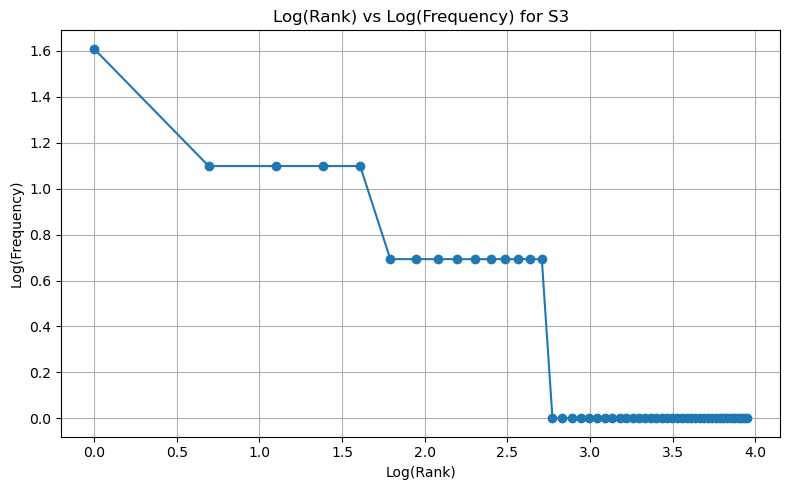

In [38]:
word_frequencies = Counter(S3)

# Sort frequencies in descending order
sorted_frequencies = sorted(
    word_frequencies.values(),
    reverse=True
)

# Assign ranks starting from 1
ranks = list(range(1, len(sorted_frequencies) + 1))

# Calculate logarithms
import math

log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [
    math.log(frequency)
    for frequency in sorted_frequencies
]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(log_ranks, log_frequencies, marker='o')

plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")

plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
from nltk.util import bigrams

# Bigrams for S1
S1_bigrams = list(bigrams(S1))
S1_bigram_frequencies = Counter(S1_bigrams)

# Bigrams for S3
S3_bigrams = list(bigrams(S3))
S3_bigram_frequencies = Counter(S3_bigrams)

print("Top 5 bigrams in S1:")
for bigram, frequency in S1_bigram_frequencies.most_common(5):
    print(bigram, ":", frequency)

print("\nTop 5 bigrams in S3:")
for bigram, frequency in S3_bigram_frequencies.most_common(5):
    print(bigram, ":", frequency)

Top 5 bigrams in S1:
('.', 'The') : 8
('.', 'Please') : 3
('Please', 'help') : 3
('help', '.') : 3
('The', 'same') : 3

Top 5 bigrams in S3:
('please', 'help') : 3
('problem', 'occurs') : 3
('failed', 'open') : 2
('password', 'stopped') : 1
('stopped', 'syncing') : 1


In [40]:
top_s1_bigrams = S1_bigram_frequencies.most_common(5)
top_s3_bigrams = S3_bigram_frequencies.most_common(5)

bigrams_df = pd.DataFrame({
    "Rank": range(1, 6),
    "S1 Bigram": [" ".join(pair) for pair, count in top_s1_bigrams],
    "S1 Frequency": [count for pair, count in top_s1_bigrams],
    "S3 Bigram": [" ".join(pair) for pair, count in top_s3_bigrams],
    "S3 Frequency": [count for pair, count in top_s3_bigrams]
})

display(bigrams_df)

,Rank,S1 Bigram,S1 Frequency,S3 Bigram,S3 Frequency
0,1,. The,8,please help,3
1,2,. Please,3,problem occurs,3
2,3,Please help,3,failed open,2
3,4,help .,3,password stopped,1
4,5,The same,3,stopped syncing,1
